# Assignment 1 — Data Exploration and Cleaning: Hashtags

Each row represents a hashtag–post association. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\bucco\Desktop\Laboratory of Data Science\project")
DATA_DIR = PROJECT_DIR / "Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-" / "Project_Data"
ARFF_PATH = PROJECT_DIR / "code_project" / "data" / "Additional_Data" / "additional_truths.arff"
EXPORT = False


In [2]:
with (DATA_DIR / "hashtags.json").open(encoding="utf-8") as file:
    data = json.load(file, parse_int=str, parse_float=str)
df_raw = pd.DataFrame(data, dtype="string")
del data
original_columns = df_raw.columns.tolist()
print("Rows and columns:", df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({"Missing": df_raw.isna().sum(), "Blank": [df_raw[c].str.strip().eq("").sum() for c in df_raw], "Distinct": df_raw.nunique()}))


Rows and columns: (205214, 5)


,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
0,1,2022-09-14 17:29:14.578577,MarkGeist,18,1
1,2,2022-09-14 17:34:04.180279,LIVGolf,21,2
2,2,2022-09-14 17:34:04.180279,LIVGolf,478624,2
3,3,2022-09-14 23:15:11.267669,TrumpTurnberry,37,3
4,3,2022-09-14 23:15:11.267669,TrumpTurnberry,384189,3


,Missing,Blank,Distinct
id_hashtag,0,0,21599
first_seen,0,0,21599
hashtag,0,0,21599
truth_id,0,0,75278
hashtag_id,0,0,21599


In [3]:
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)
id_columns = ['id_hashtag', 'hashtag_id', 'truth_id']
for col in id_columns:
    values = df_clean[col].str.replace(r"\.0+$", "", regex=True)
    assert values.str.fullmatch(r"\d+", na=False).all(), f"Inspect invalid {col} values."
    df_clean[col] = pd.to_numeric(values, errors="raise").astype("Int64")
    assert df_clean[col].gt(0).all()
print("Exact duplicate rows removed:", removed_duplicates)
features = pd.DataFrame({"row_id": np.arange(len(df_clean))})


Exact duplicate rows removed: 2


## Hashtag text, HTML contamination, and mappings

Case and spelling remain unchanged in the clean data. A lowercase feature supports exploratory grouping, without merging source hashtag IDs. HTML-contaminated text is recovered only when its leading name agrees with the embedded Truth Social tag URL.


In [4]:
features["hashtag_original"] = df_clean["hashtag"]
malformed = df_clean["hashtag"].str.contains(r"rel\s*=|<[^>]+>", regex=True, na=False)
url_candidate = df_clean["hashtag"].str.extract(r"truthsocial\.com/tags/([A-Za-z0-9_]+)", expand=False)
prefix_candidate = df_clean["hashtag"].str.extract(r"^([A-Za-z0-9_]+)['\"]?\s+rel=", expand=False)
recoverable = malformed & url_candidate.notna() & url_candidate.eq(prefix_candidate).fillna(False)
df_clean.loc[recoverable, "hashtag"] = url_candidate[recoverable]
features["hashtag_recovered"] = recoverable
features["malformed_unresolved"] = malformed & ~recoverable
features["identifier_mismatch"] = df_clean["id_hashtag"].ne(df_clean["hashtag_id"])
features["missing_hashtag"] = df_clean["hashtag"].isna()
features["hashtag_normalized"] = df_clean["hashtag"].str.lstrip("#").str.casefold()
features["hashtag_length"] = df_clean["hashtag"].str.len().astype("Int64")
print("Malformed values:", malformed.sum(), "Recovered:", recoverable.sum())
display(df_clean.loc[recoverable, ["id_hashtag", "hashtag", "truth_id"]])
names_per_id = df_clean.groupby("id_hashtag")["hashtag"].nunique()
features["id_has_multiple_names"] = df_clean["id_hashtag"].map(names_per_id).gt(1)
print("IDs associated with multiple names:", names_per_id.gt(1).sum())
print("Repeated hashtag–post pairs:", df_clean.duplicated(["truth_id", "hashtag_id"]).sum())


Malformed values: 1 Recovered: 1
IDs associated with multiple names: 0
Repeated hashtag–post pairs: 0


,id_hashtag,hashtag,truth_id
189771,20299,LegalImmigrants,718216


In [5]:
df_clean["first_seen"] = pd.to_datetime(df_clean["first_seen"], format="ISO8601", errors="raise")
features["first_seen_month"] = df_clean["first_seen"].dt.strftime("%Y-%m")
features["first_seen_after_reference_date"] = df_clean["first_seen"].ge(pd.Timestamp("2026-11-12"))
print("First-seen range:", df_clean["first_seen"].min(), "to", df_clean["first_seen"].max())
print("Distinct first_seen values per hashtag ID:")
display(df_clean.groupby("hashtag_id")["first_seen"].nunique().value_counts().to_frame("Hashtag IDs"))


First-seen range: 2022-09-14 17:29:14.578577 to 2022-11-10 19:09:27.834105
Distinct first_seen values per hashtag ID:


,Hashtag IDs
first_seen,
1,21599


## Post references and recovery assessment

`truth_id` is checked as an internal main-corpus ID first, then against exact ARFF source IDs. A coincidental external-ID match is reported as a candidate, not used to rewrite the foreign key. Missing records in a partial corpus do not establish that the relationship is false.

The ARFF reference reader uses only the leading and trailing metadata fields of the supplied one-record-per-line file. It does not parse post text or claim to be a general ARFF reader.


In [6]:
needed_internal = set(df_clean["truth_id"].astype("string"))
needed_external = needed_internal.copy()


In [7]:
arff_rows = []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not in_data:
            in_data = line.lower() == "@data"
            continue
        if not line or line.startswith("%"):
            continue
        first = line.split(",", 2)
        tail = line.rsplit(",", 3)
        assert first[0].isdigit() and len(tail) == 4
        arff_rows.append((first[0], tail[1].strip("'\""), tail[2], first[1].strip("'\"")))
arff_ref = pd.DataFrame(arff_rows, columns=["source_id", "external_id", "author", "timestamp"], dtype="string")
del arff_rows
assert arff_ref["source_id"].is_unique
assert arff_ref["source_id"].eq(arff_ref["external_id"]).all()
arff_ref["author"] = pd.to_numeric(arff_ref["author"].str.replace(r"\.0+$", "", regex=True)).astype("Int64")
arff_ref["timestamp"] = pd.to_datetime(arff_ref["timestamp"], format="ISO8601", errors="raise")


In [8]:
main_ids, parts = set(), []
for chunk in pd.read_csv(DATA_DIR / "truths.csv", usecols=["id", "external_id", "url", "author", "timestamp"], dtype="string", keep_default_na=False, chunksize=100000):
    chunk["id"] = chunk["id"].str.replace(r"\.0+$", "", regex=True)
    assert chunk["id"].str.fullmatch(r"\d+", na=False).all()
    main_ids.update(chunk["id"])
    external = chunk["external_id"].where(chunk["external_id"].str.fullmatch(r"\d+", na=False))
    url_id = chunk["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/?#]+/posts/(\d+)/?$", expand=False)
    url_id = url_id.combine_first(chunk["url"].where(chunk["url"].str.fullmatch(r"\d+", na=False)))
    mismatch = external.notna() & url_id.notna() & external.ne(url_id).fillna(False)
    chunk["external_id"] = external.combine_first(url_id).mask(mismatch)
    keep = chunk["id"].isin(needed_internal) | chunk["external_id"].isin(needed_external)
    parts.append(chunk.loc[keep, ["id", "external_id", "author", "timestamp"]].copy())
main_ref = pd.concat(parts, ignore_index=True).drop_duplicates()
del parts, chunk
main_ref["author"] = pd.to_numeric(main_ref["author"].str.replace(r"\.0+$", "", regex=True).replace("", pd.NA), errors="raise").astype("Int64")
main_ref["timestamp"] = pd.to_datetime(main_ref["timestamp"], format="ISO8601", errors="raise")
print("Distinct main-corpus IDs:", len(main_ids))


Distinct main-corpus IDs: 1038821


In [9]:
truth_keys = df_clean["truth_id"].astype("string")
features["post_reference_status"] = "missing"
features.loc[truth_keys.isin(main_ids), "post_reference_status"] = "main_internal"
arff_match = ~truth_keys.isin(main_ids) & truth_keys.isin(arff_ref["source_id"])
features.loc[arff_match, "post_reference_status"] = "arff_source_id"
external_candidate = ~truth_keys.isin(main_ids) & truth_keys.isin(main_ref["external_id"])
features["external_namespace_candidate"] = external_candidate
unresolved_post = features["post_reference_status"].eq("missing")
display(features["post_reference_status"].value_counts().to_frame("Relationships"))
print("Unresolved rows with an external-ID candidate:", (unresolved_post & external_candidate).sum())
display(df_clean.loc[unresolved_post].head(5))


Unresolved rows with an external-ID candidate: 0


,Relationships
post_reference_status,
main_internal,168587
missing,36625


,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
19,5,2022-09-14 23:15:39.463634,Alaska,562384,5
31,5,2022-09-14 23:15:39.463634,Alaska,892604,5
33,5,2022-09-14 23:15:39.463634,Alaska,970375,5
61,7,2022-09-15 01:56:29.460178,CrookedHillary,903228,7
62,7,2022-09-15 01:56:29.460178,CrookedHillary,958197,7


## Frequencies, concentration, and outliers

`first_seen` is collection metadata for a hashtag, not automatically the creation time of each linked post. Hashtag names can suggest topics, but do not establish a post category or location by themselves. Sharing a hashtag with an ARFF post cannot recover a missing post ID.


,Distinct linked posts
hashtag,
Truth,11206
TrumpTruths,6466
DT47,3801
MAGA,3199
truth,2959
Trump,2278
TruthSocial,1954
FJB,1926
Covfefe,1920


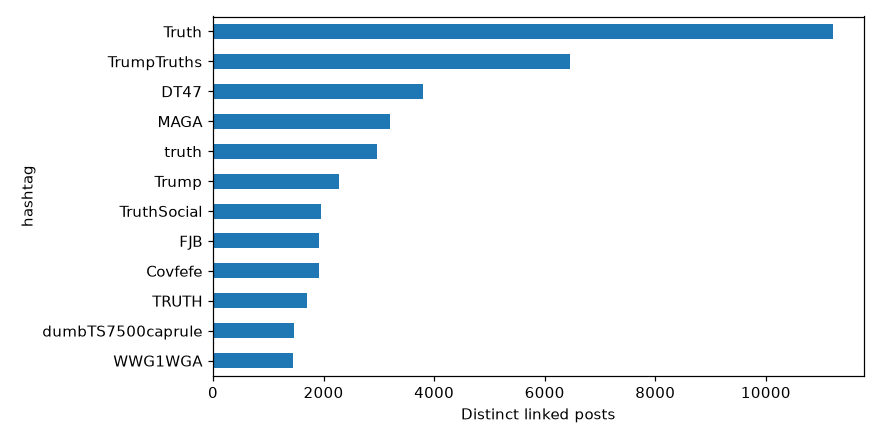

,Hashtags per linked post
count,75278.000000
mean,2.726055
std,3.652068
min,1.000000
50%,1.000000
90%,5.000000
95%,8.000000
99%,19.000000
max,56.000000


,Distinct hashtags
truth_id,
139154,56
425689,54
559479,53
681001,53
570641,52


In [10]:
frequency = df_clean.groupby("hashtag")["truth_id"].nunique().sort_values(ascending=False)
display(frequency.head(15).to_frame("Distinct linked posts"))
frequency.head(12).sort_values().plot.barh(figsize=(8, 4))
plt.xlabel("Distinct linked posts")
plt.tight_layout()
plt.show()
tags_per_post = df_clean.groupby("truth_id")["hashtag_id"].nunique()
display(tags_per_post.describe(percentiles=[.5, .9, .95, .99]).to_frame("Hashtags per linked post"))
q1, q3 = tags_per_post.quantile([.25, .75])
features["many_hashtags_on_post"] = df_clean["truth_id"].isin(tags_per_post[tags_per_post > q3 + 1.5 * (q3 - q1)].index)
display(tags_per_post.nlargest(5).to_frame("Distinct hashtags"))


## Final validation and exports

We preserve the original column structure. Features retain `row_id`, the zero-based row position in the cleaned export. Unresolved links remain in the cleaned data and are also listed for review.


In [11]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final[id_columns].notna().all().all()
assert df_final[id_columns].gt(0).all().all()
assert len(features) == len(df_final)
assert features["row_id"].tolist() == list(range(len(df_final)))
review_mask = (
    unresolved_post
    | features["malformed_unresolved"]
    | features["missing_hashtag"]
    | features["identifier_mismatch"]
    | features["id_has_multiple_names"]
    | features["first_seen_after_reference_date"]
)
issues = pd.concat([features.loc[review_mask], df_final.loc[review_mask]], axis=1)
quality_summary = pd.Series({
    "Original rows": len(df_raw), "Exact duplicates removed": removed_duplicates,
    "Cleaned rows": len(df_final), "Rows for review": int(review_mask.sum()),
    "Missing cells after cleaning": int(df_final.isna().sum().sum())
}, name="Count")
display(quality_summary.to_frame())


,Count
Original rows,205214
Exact duplicates removed,2
Cleaned rows,205212
Rows for review,36625
Missing cells after cleaning,0


In [12]:
OUTPUT_DIR = Path.cwd() / "output_hashtags"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(OUTPUT_DIR / "hashtags_clean.csv.gz", index=False, chunksize=50000)
    features.to_csv(OUTPUT_DIR / "hashtags_features.csv.gz", index=False, chunksize=50000)
    issues.to_csv(OUTPUT_DIR / "hashtags_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "hashtags_quality_summary.csv", index_label="Check")
    print("Exported to:", OUTPUT_DIR.resolve())
else:
    print("Analysis and cleaning complete. Set EXPORT = True to save datasets.")


Analysis and cleaning complete. Set EXPORT = True to save datasets.


## Conclusions and Assignment 1 coverage

**Observed results:** Original rows: 205,214; Exact duplicates removed: 2; Cleaned rows: 205,212; Rows for review: 36,625; Missing cells after cleaning: 0.

Only independently agreeing pieces of the contaminated value support a hashtag correction. Duplicate associations are removed only when the complete rows agree. Valid Unicode or unusual tag names are not automatically deleted. Orphan relationships, identifier conflicts, and suspicious collection dates remain documented; long names and high tag counts are retained for inspection.

This notebook covers structure and types, missing values, duplicates and mappings, data-specific anomalies, outliers, post/user integrity where applicable, recovery assessments, derived features, and validated cleaning. Only supplied files are used. The full ARFF-to-Truths integration is implemented in `04_additional_truths_complete.ipynb`; this notebook's reference checks do not replace it.

Compressed CSVs are readable directly with `pd.read_csv(path)`. Original invalid values and unresolved cases remain traceable in features or issue tables. The sources are the supplied dataset, related original datasets, the Assignment 1 instructions, and its original exploration/cleaning notebooks.
